# Chemical and elastic phase separation

I use the website’s dimensionless two-dimensional model, with periodic boundaries, unit mobility and unit gradient coefficient. Composition c is a conserved field. The bulk free-energy density is c²(1-c)². Its derivative contributes 2c(1-c)(1-2c) to chemical potential. The elastic coefficient B(k) is zero for the chemical example. The elastic example uses a homogeneous 2D constitutive model with zero mean stress; it is not a calibrated alloy or a plane-strain reduction of a 3D eigenstrain.

I write one part, test it, then continue. Run the cells in order. This short lesson checks the method; it does not replace the complete simulation or establish convergence.

**Using my code.** I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research (including academic research) and commercial use require my explicit written permission. Earlier MIT and GPL releases retain their existing permissions. Read the [code-use terms](https://saswataiith.github.io/files/CODE-USE-TERMS.txt). Request permission at saswata_at_msme.iith.ac.in. These terms apply to code; teaching text and figures have separate terms.


I choose the mean composition explicitly: `c0 = 0.5`. The small seeded perturbation is added once, at the start. The printed mean checks that the initialization retains this chosen composition. For the chemical free energy $f(c)=c^2(1-c)^2$, its inflection points are $(3-\sqrt{3})/6 \approx 0.2113$ and $(3+\sqrt{3})/6 \approx 0.7887$. Between them, $f^{\prime\prime}(c_0)<0$, so sufficiently long-wavelength composition fluctuations grow. Elasticity adds a further penalty and can narrow this unstable range. Outside the chemical spinodal, small fluctuations decay; nucleation requires a sufficiently large fluctuation or a suitable seed.

Initial random perturbations are different from sustained thermal fluctuations. A thermal Cahn–Hilliard–Cook model uses a conserved random flux, with Gaussian white-noise statistics in the ideal continuum model and amplitude fixed by fluctuation–dissipation. Its discretization depends on cell size and time step. I do not add thermal noise during the evolution here. [Cook’s original paper](https://doi.org/10.1016/0001-6160(70)90144-6).

## Step 1: Create wave numbers and the initial field

I start with the chemical case. The grid spacing is one dimensionless length unit. I remove the mean of the seeded random perturbation so that the initial mean composition is exactly 0.5 to floating-point accuracy.

I use NumPy’s random generator with seed 714. Reusing the seed reproduces the initial field in this environment. I subtract the perturbation’s mean to retain mean composition 0.5.

In [1]:
import numpy as np
n = 64
dt = 0.2
k = 2 * np.pi * np.fft.fftfreq(n)
kx, ky = np.meshgrid(k, k, indexing="ij")
k2 = kx**2 + ky**2
c0 = 0.5
seed = 714
rng = np.random.default_rng(seed)
noise = 0.02 * (rng.random((n, n)) - 0.5)
noise -= noise.mean()
initial = c0 + noise
assert abs(initial.mean() - c0) < 1e-12
assert k2[0, 0] == 0
print("Mean composition =", initial.mean())

Mean composition = 0.5


## Step 2: One update and my conservation check

The gradient and elastic terms are implicit; the nonlinear bulk derivative is explicit. The zero Fourier mode is unchanged because k² is zero there. I check the mean and finite values after one update. These checks do not prove energy stability.

In [2]:
chemical_kernel = np.zeros_like(k2)
bulk_derivative = 2 * initial * (1 - initial) * (1 - 2 * initial)
numerator = np.fft.fft2(initial) - dt * k2 * np.fft.fft2(bulk_derivative)
denominator = 1 + dt * k2 * (k2 + chemical_kernel)
one_step = np.fft.ifft2(numerator / denominator).real
assert np.isfinite(one_step).all()
assert abs(one_step.mean() - initial.mean()) < 1e-12
print("Mean change after one update:", one_step.mean() - initial.mean())

Mean change after one update: 0.0


## Step 3: Add the elastic kernel separately

I use the existing tested kernel rather than introducing a different formula in this notebook. C11, C12 and C44 are dimensionless elastic stiffnesses here. The dilatational eigenstrain is dimensionless. I check the isotropic limit, in which the nonzero-mode kernel has no angular dependence. I also check that zero misfit removes the elastic contribution.

A real composition field has paired Fourier coefficients. For each wave vector \(\mathbf{k}\), the coefficient at \(-\mathbf{k}\) is its complex conjugate: the real parts are equal and the imaginary parts have opposite signs,
\[\widehat c(-\mathbf{k})=\widehat c(\mathbf{k})^*.\]
Here the star means complex conjugation. This pairing is what allows the inverse Fourier transform to recover a real field.

The elastic kernel in this calculation is real. To preserve that pairing during an update, it must have the same value at opposite wave vectors: \(B(-\mathbf{k})=B(\mathbf{k})\). This symmetry already holds analytically for the dilatational kernel used here. I make it explicit in the stored numerical array by replacing each pair with its average.

The array `partner = (-np.arange(n)) % n` finds the opposite Fourier index. For an eight-point direction it gives `[0, 7, 6, 5, 4, 3, 2, 1]`: index 1 pairs with 7, and index 2 with 6. Index 0 pairs with itself. On an even grid, index `n // 2`, the Nyquist index, also pairs with itself in that direction. It represents an alternating plus/minus pattern at successive grid points; its positive- and negative-frequency versions have identical samples. In two dimensions I apply this rule to both indices. `np.ix_(partner, partner)` selects the partner of every array entry; averaging the original and reordered arrays gives matching values for every pair. This is an average of kernel coefficients in Fourier space, not a smoothing of the composition image.

In [3]:
def kernel(kx, ky, c11=4.0, c12=2.0, c44=3.0, eigenstrain=0.2):
    """B = E:C:E - (sigma0.n).Q^-1.(sigma0.n), E=eigenstrain*I.
    Q_ik=C_ijkl*n_j*n_l; Q11=C11*nx²+C44*ny² (not C12).
    This is a 2D constitutive model, not a reduction with epsilon_zz eigenstrain.
    """
    k2 = kx * kx + ky * ky
    radius = np.sqrt(np.where(k2 == 0, 1.0, k2))
    nx, ny = (kx / radius, ky / radius)
    q11 = c11 * nx * nx + c44 * ny * ny
    q22 = c44 * nx * nx + c11 * ny * ny
    q12 = (c12 + c44) * nx * ny
    det = q11 * q22 - q12 * q12
    det = np.where(k2 == 0, 1.0, det)
    stress = (c11 + c12) * eigenstrain
    b = 2 * (c11 + c12) * eigenstrain ** 2 - stress ** 2 * (q22 * nx * nx - 2 * q12 * nx * ny + q11 * ny * ny) / det
    return np.where(k2 == 0, 0.0, b)

angles = np.linspace(0, 2 * np.pi, 33)
isotropic = kernel(np.cos(angles), np.sin(angles), c11=4, c12=2, c44=1)
assert np.ptp(isotropic) < 1e-12
assert np.allclose(kernel(kx, ky, eigenstrain=0), 0)
elastic_kernel = kernel(kx, ky, c11=4, c12=2, c44=3, eigenstrain=0.2)
# Find the opposite Fourier index in each direction.
partner = (-np.arange(n)) % n
# Give opposite-wave-vector partners the same real kernel value.
elastic_kernel = 0.5 * (elastic_kernel + elastic_kernel[np.ix_(partner, partner)])
assert np.isfinite(elastic_kernel).all()
print("Isotropic angular variation:", np.ptp(isotropic))

Isotropic angular variation: 3.3306690738754696e-16


## Step 4: Compare short evolutions with the same initial field

I advance both cases from identical fields for 50 steps. This is a short execution and conservation check. The complete program supplies longer runs and free-energy records. Timestep and spatial refinement are separate questions and have not been established by this notebook.

Final time: 10.0
Field RMS difference: 0.005768896080992374


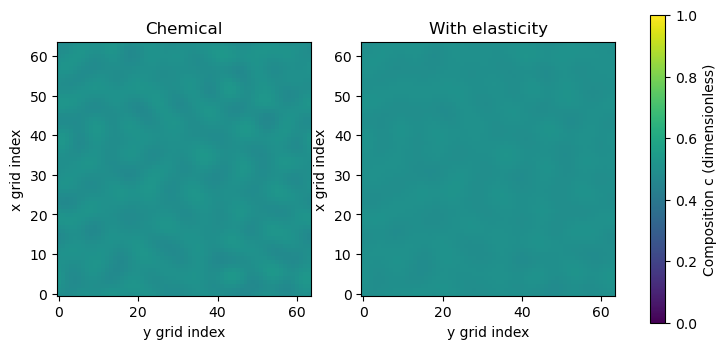

In [4]:
chemical = initial.copy()
elastic = initial.copy()
for step in range(50):
    chemical_bulk = 2 * chemical * (1 - chemical) * (1 - 2 * chemical)
    chemical_spectrum = np.fft.fft2(chemical) - dt * k2 * np.fft.fft2(chemical_bulk)
    chemical = np.fft.ifft2(chemical_spectrum / (1 + dt*k2*(k2 + chemical_kernel))).real
    elastic_bulk = 2 * elastic * (1 - elastic) * (1 - 2 * elastic)
    elastic_spectrum = np.fft.fft2(elastic) - dt * k2 * np.fft.fft2(elastic_bulk)
    elastic = np.fft.ifft2(elastic_spectrum / (1 + dt*k2*(k2 + elastic_kernel))).real
for result in (chemical, elastic):
    assert np.isfinite(result).all()
    assert abs(result.mean() - initial.mean()) < 1e-10
assert np.linalg.norm(chemical - elastic) > 0
print("Final time:", 50 * dt)
print("Field RMS difference:", np.sqrt(np.mean((chemical - elastic)**2)))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, field, name in zip(axes, [chemical, elastic], ["Chemical", "With elasticity"]):
    image = ax.imshow(field, vmin=0, vmax=1, origin="lower")
    ax.set_title(name)
    ax.set_xlabel("y grid index")
    ax.set_ylabel("x grid index")
fig.colorbar(image, ax=axes, label="Composition c (dimensionless)")
plt.show()

## Continue with the complete program

The original complete program is `../phase_field.py`. Its parameters, source credits and output commands are retained. These short examples use smaller workloads for learning; they are not a rerun of every result on the website.